# Quickstart: simulate, analyze, plot

This notebook runs the whole method on the CPU in a few minutes:

1. simulate two 8 s segments of data in the LIGO Hanford and Livingston detectors, one with a binary black-hole merger and one with noise only;
2. compute, for each segment, the likelihood ratio marginalized over sky position, orientation, phase, arrival time and distance, on a grid of source-frame primary mass and redshift;
3. draw the posterior of the mass and the redshift, with the true values.

It needs the tables (40 GB) in `tables/redshift/`:

    python scripts/fetch_tables.py 23578160

On the CPU the tables are mapped from disk (`mmap=True`), so the memory they need is only what the operating system caches.

In [1]:
import sys
sys.path.insert(0, '../src')

import time
import numpy as np
import matplotlib.pyplot as plt
from astropy.cosmology import Planck18, z_at_value
import astropy.units as u

from exmarg import pp
import exmarg.search as search
from exmarg.search.segments import D0       # reference distance of the tables (Mpc): y = D0 / D_L

## 1. Simulate the data

`pp.simulate` draws the sky position, orientation, phase and arrival time at random and adds the signal of an equal-mass binary
without spin to Gaussian noise (design noise curve, 20-512 Hz). The distance is set through `y = D0 / D_L`.
We first simulate the merger at `y = 1`, then rescale `y` so that the network signal-to-noise ratio is 6, below the usual detection threshold of 8 (same seed, so the
same noise and the same angles).

In [2]:
M_det = 60.0                   # detector-frame total mass (solar masses)
target_snr = 6.0
T, fmin, fmax = 8.0, 20.0, 512.0

def simulate(y, seed):
    return pp.simulate(1, seed, lambda rng: (M_det, 1.0, 0.0), lambda rng: y, T, fmin, fmax)

_, _, snr = simulate(1.0, seed=13)
y_true = target_snr / snr[0]
signal, truth, snr = simulate(y_true, seed=13)
noise, _, _ = simulate(1e-8, seed=8)          # a merger at y = 1e-8 adds nothing: noise only

segments = dict(signal)
segments['d_H'] = np.concatenate([signal['d_H'], noise['d_H']])
segments['d_L'] = np.concatenate([signal['d_L'], noise['d_L']])

D_L = D0 / y_true
z_true = z_at_value(Planck18.luminosity_distance, D_L * u.Mpc).value
m1_true = M_det / 2 / (1 + z_true)
print('merger: M_det = %.0f, D_L = %.0f Mpc, z = %.3f, source-frame m1 = %.1f, network SNR = %.1f' % (M_det, D_L, z_true, m1_true, snr[0]))

merger: M_det = 60, D_L = 3969 Mpc, z = 0.645, source-frame m1 = 18.2, network SNR = 6.0


## 2. Analyze

The template bank is 120 detector-frame total masses from 20 to 200. For every template the code matched-filters the two
detectors and reads the tables at every arrival time and every delay between the detectors; `pe_redshift` then turns the
result into the likelihood ratio on a grid of (m1, z) and its average over the prior, the Bayes factor ln B.

In [3]:
start = time.time()
store = search.load_redshift_store('../tables/redshift', mmap=True)
bank = search.mass_bank(np.geomspace(20, 200, 120), segments, 'cpu')
print('tables mapped and bank built in %.0f s' % (time.time() - start))

start = time.time()
result = search.pe_redshift(segments, bank, store, mdet_range=(20.0, 200.0))     # prior on M_det = the range of the bank
seconds = time.time() - start
print('2 segments in %.0f s on the CPU' % seconds)
print('ln B, segment with the merger: %.2f' % result['ln_b'][0])
print('ln B, noise only:              %.2f' % result['ln_b'][1])

tables mapped and bank built in 0 s


2 segments in 28 s on the CPU
ln B, segment with the merger: 6.31
ln B, noise only:              -0.02


## 3. Plot

The posterior is the likelihood ratio times the prior used for ln B: uniform in detector-frame mass, uniform in volume
(proportional to D_L² in luminosity distance).

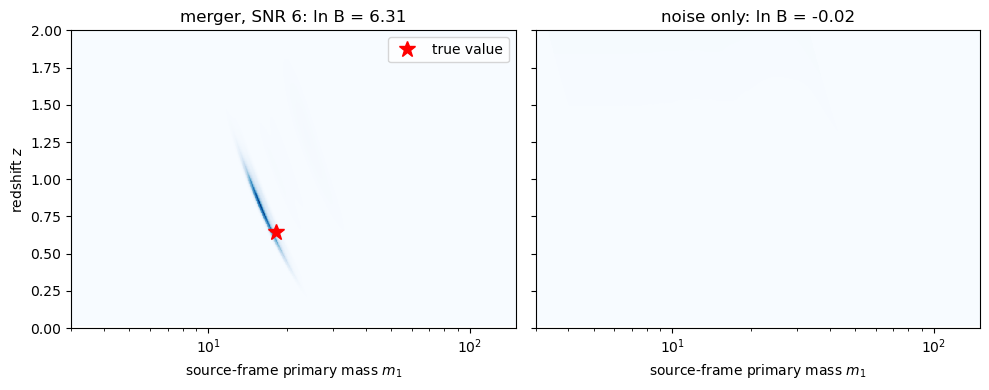

In [4]:
m1, z = result['m1'], result['z']
DL = Planck18.luminosity_distance(z).value
prior = (1 + z) * DL ** 2 * np.gradient(DL, z)
inside = (2 * m1[:, None] * (1 + z[None, :]) >= 20) & (2 * m1[:, None] * (1 + z[None, :]) <= 200)

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, row, title in zip(axes, (0, 1), ('merger, SNR %.0f' % snr[0], 'noise only')):
    lp = np.where(inside, result['ln_lambda'][row] + np.log(prior)[None, :], -np.inf)
    post = np.exp(lp - lp[np.isfinite(lp)].max())
    ax.pcolormesh(m1, z, post.T, shading='auto', cmap='Blues')
    ax.set_xscale('log')
    ax.set_xlabel('source-frame primary mass $m_1$')
    ax.set_title('%s: ln B = %.2f' % (title, result['ln_b'][row]))
axes[0].plot(m1_true, z_true, 'r*', ms=12, label='true value')
axes[0].legend(loc='upper right')
axes[0].set_ylabel('redshift $z$')
axes[0].set_ylim(0, 2)
plt.tight_layout()
plt.show()